# Лабораторна робота №4: дерева рішень і ансамблі на даних з пропусками

**Мета:** порівняти Decision Tree, Random Forest і XGBoost на датасеті Annealing, де дуже багато пропущених значень.
Дивимось, чи допомагають індикатори пропусків, підбираємо гіперпараметри через Optuna без витоку даних,
чесно оцінюємо моделі вкладеною крос-валідацією, перевіряємо різницю статистичним тестом і пробуємо пояснити,
що саме моделі "бачать" (permutation importance, SHAP).

Усі джерела випадковості беруть одну константу `SEED = 42 + N`, де `N = 7`.
Версії бібліотек виводяться в першій клітинці, повний список є в `requirements.txt` у корені репозиторію.

## 0. Бібліотеки

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
import scipy
import sklearn
import xgboost
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

optuna.logging.set_verbosity(optuna.logging.WARNING)


N = 7
SEED = 42 + N
N_TRIALS = 30
print('SEED =', SEED)
for lib in [np, pd, sklearn, xgboost, optuna, shap, scipy]:
    print(f'{lib.__name__:10s} {lib.__version__}')

SEED = 49
numpy      2.5.4
pandas     3.0.6
sklearn    1.9.1
xgboost    3.4.1
optuna     5.0.0
shap       0.54.1
scipy      1.18.1


---
## 1. Первинний аналіз даних

In [2]:
data = fetch_openml(name='anneal', version=1, as_frame=True)
X, y = data.data.copy(), data.target.astype(str)

cat_cols = X.select_dtypes(exclude='number').columns
X[cat_cols] = X[cat_cols].astype(object)

print('Observations:', X.shape[0], '| features:', X.shape[1])
print(X.dtypes.value_counts())
print('Numeric features:', X.select_dtypes('number').columns.tolist())

Observations: 898 | features: 38
object     32
int64       4
float64     2
Name: count, dtype: int64
Numeric features: ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']


Беремо версію з OpenML, у ній **898 об'єктів** і 38 ознак. Числових ознак лише 6, решта категоріальні.
Серед категоріальних є й такі, що виглядають як числа (наприклад, `bore`), але в OpenML вони записані як категорії,
тож так їх і лишаємо.

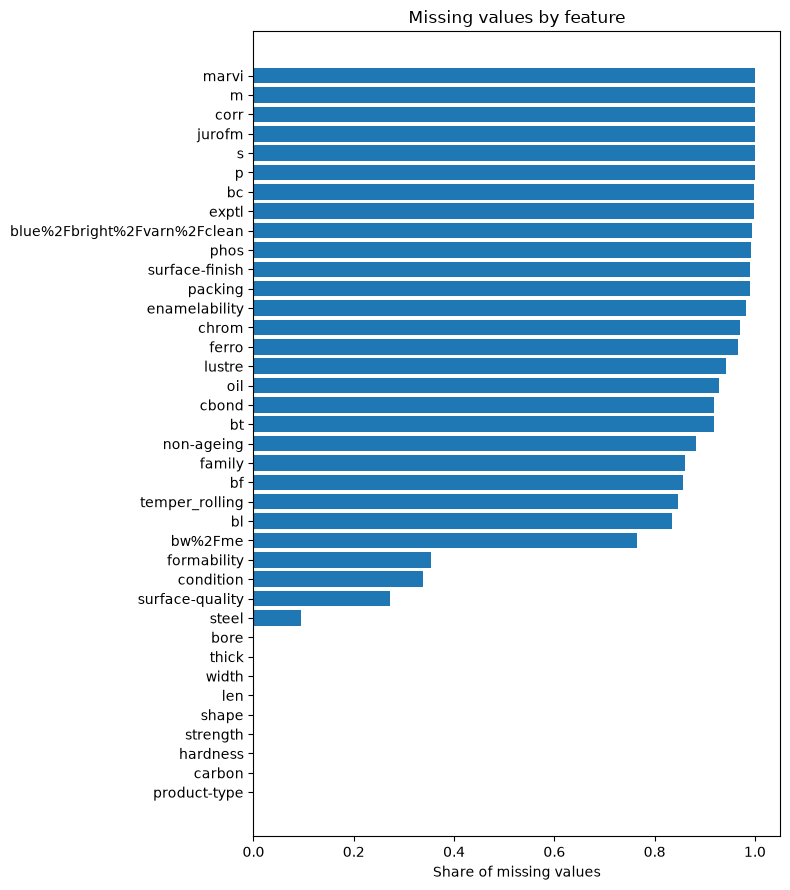

Features with >50% missing: 25 of 38


In [3]:
missing = X.isna().mean().sort_values()
plt.figure(figsize=(8, 9))
plt.barh(missing.index, missing.values)
plt.xlabel('Share of missing values')
plt.title('Missing values by feature')
plt.tight_layout()
plt.show()
print('Features with >50% missing:', (missing > 0.5).sum(), 'of', len(missing))

**Висновок.** Пропусків дуже багато: у 25 з 38 ознак пропущено більше половини значень, а 6 ознак порожні повністю.
Зате 9 ознак, зокрема всі числові, заповнені повністю або майже повністю.

In [4]:
nunique = X.nunique(dropna=True)
empty_cols = nunique[nunique == 0].index.tolist()
const_cols = [c for c in X.columns if nunique[c] == 1 and X[c].notna().all()]
print('Completely empty:', empty_cols)
print('Constant (no missing):', const_cols)
X = X.drop(columns=empty_cols + const_cols)
print('Shape after dropping:', X.shape)

# features with a single value and NaN everywhere else
one_value = [c for c in X.columns if nunique[c] == 1]
pd.DataFrame({'value': [X[c].dropna().iloc[0] for c in one_value],
              'missing share': X[one_value].isna().mean().round(3).values}, index=one_value)

Completely empty: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Constant (no missing): ['product-type']
Shape after dropping: (898, 31)


,value,missing share
temper_rolling,T,0.847
non-ageing,N,0.883
surface-finish,P,0.990
bc,Y,0.999
bf,Y,0.856
bt,Y,0.918
bl,Y,0.834
chrom,C,0.971
phos,P,0.992
cbond,Y,0.918


**Висновок.** Видаляємо 6 повністю порожніх колонок, бо в них немає жодної інформації, і `product-type`, бо в ній
одне значення без пропусків. Отже, лишається 31 ознака.

Цікаво, що ще 13 ознак мають **одне значення, а замість решти NaN**. Наприклад, `bt` дорівнює або `Y`, або пропуску.
Згідно з описом датасету, пропуск тут часто означає "не застосовно", тобто пропуск структурний. Якщо заповнити такі
колонки модою, вони стануть константою, і вся інформація зникне. Зберегти її можуть лише індикатори пропусків.

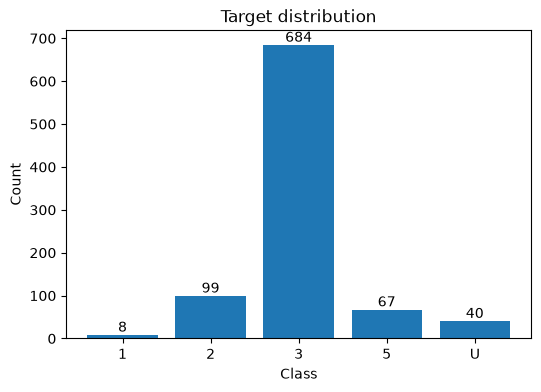

class
1    0.009
2    0.110
3    0.762
5    0.075
U    0.045
Name: count, dtype: float64


In [5]:
counts = y.value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
for i, value in enumerate(counts.values):
    plt.text(i, value + 8, str(value), ha='center')
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Target distribution')
plt.show()
print((counts / counts.sum()).round(3))

**Висновок.** Дисбаланс дуже сильний: клас `3` займає 76% даних, а клас `1` має лише 8 об'єктів (менше 1%).
Класу `4`, який є в документації, у даних немає взагалі. Клас `1` залишаємо, бо це реальний клас, а викинувши його,
ми б спростили задачу. Але він створює проблему для крос-валідації: у train потрапить 6 об'єктів, і при 5 зовнішніх
блоках у кожному блоці буде лише 1–2 таких об'єкти. Тому macro F1 буде дуже "стрибати" від блоку до блоку, і
внутрішня CV має лише 3 блоки.

### Механізм пропусків

Для ознак з найбільшою часткою пропусків будуємо таблицю "пропуск / не пропуск × клас" і перевіряємо незалежність
критерієм χ². Беремо 5 ознак з найбільшою часткою пропусків серед тих, де є хоча б 10 заповнених значень:
якщо заповнених значень одне-два, тест нічого не покаже.

In [6]:
filled = X.notna().sum()
top_missing = X.isna().mean()[filled >= 10].sort_values(ascending=False).head(5).index

chi_rows = []
for col in top_missing:
    table = pd.crosstab(X[col].isna(), y)
    chi2, p, dof, expected = stats.chi2_contingency(table)
    chi_rows.append({'feature': col, 'missing share': round(X[col].isna().mean(), 3),
                     'chi2': round(chi2, 1), 'p-value': p, 'min expected': round(expected.min(), 2)})
chi_df = pd.DataFrame(chi_rows)
chi_df

,feature,missing share,chi2,p-value,min expected
0,enamelability,0.982,44.4,5.203932e-09,0.14
1,chrom,0.971,332.1,1.287681e-70,0.23
2,ferro,0.967,384.9,4.964091e-82,0.27
3,lustre,0.943,13.0,1.122049e-02,0.45
4,oil,0.929,24.5,6.257161e-05,0.57


In [7]:
# example of one contingency table
pd.crosstab(X[top_missing[0]].isna(), y, rownames=[f'{top_missing[0]} is missing'])

class,1,2,3,5,U
enamelability is missing,,,,,
False,0,10,6,0,0
True,8,89,678,67,40


**Висновок.** Для всіх 5 ознак p-value < 0.05, а для `chrom` і `ferro` воно взагалі мізерне. Отже, те, чи пропущене
значення, залежить від класу. Наприклад, `enamelability` заповнена майже тільки в об'єктах класів `2` і `3`.
Очікувані частоти в деяких клітинках менші за 1, тому χ² тут грубе наближення. Але p-value настільки малі, що висновок
від цього не зміниться: **пропуски не схожі на MCAR**, вони пов'язані з класом. Значить, сам факт пропуску несе
інформацію, і індикатори пропусків мають допомогти.

In [8]:
le = LabelEncoder()
y_enc = le.fit_transform(y)
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}


---
## 2. Поділ даних і пайплайн обробки

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print('Train:', X_train.shape, '| test:', X_test.shape)
print('Train counts:', dict(zip(le.classes_, np.bincount(y_train).tolist())))
print('Test counts: ', dict(zip(le.classes_, np.bincount(y_test).tolist())))

Train: (718, 31) | test: (180, 31)
Train counts: {'1': 6, '2': 79, '3': 547, '5': 54, 'U': 32}
Test counts:  {'1': 2, '2': 20, '3': 137, '5': 13, 'U': 8}


Після поділу в train 718 об'єктів, у тесті 180. Клас `1` має 6 об'єктів у train і лише 2 у тесті. Це мінімум, з яким
ще працюють 5 зовнішніх блоків, а у внутрішніх 3 блоках на навчання лишається 3–4 таких об'єкти. XGBoost не падає,
бо кожен клас є в кожному тренувальному блоці.

**Варіант A:** медіана для числових ознак, мода для категоріальних, потім one-hot.
**Варіант B:** те саме плюс бінарні індикатори для кожної ознаки, де в train були пропуски.

Усе робиться всередині `Pipeline`, тому імпутер вчиться тільки на тренувальній частині кожного блоку
крос-валідації. Дерева в sklearn уже вміють працювати з NaN самі, але тут ми спеціально імпутуємо дані,
щоб усі три моделі отримували однаковий вхід.

In [10]:
def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)


def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'), make_column_selector()))
    return ColumnTransformer(transformers)


def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])


for flag in [False, True]:
    print('with indicators' if flag else 'without indicators', '->',
          build_preprocessor(flag).fit_transform(X_train).shape)

without indicators -> (718, 53)
with indicators -> (718, 76)


---
## 3. Базові моделі (типові гіперпараметри)

Повторна стратифікована крос-валідація 5 блоків × 3 повторення на train. Головна метрика **macro F1**,
бо класи дуже незбалансовані, і accuracy майже нічого не скаже. Для всіх моделей і обох варіантів
використовується один і той самий об'єкт `cv`, тому блоки однакові, і далі можна робити парне порівняння.

In [11]:
models = ['DT', 'RF', 'XGB']
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

cv_results = {}
for variant, with_ind in [('A', False), ('B', True)]:
    for name in models:
        cv_results[(variant, name)] = cross_validate(
            build_pipeline(name, with_ind), X_train, y_train, cv=cv, scoring=scoring)


def cv_table(variant):
    rows = {}
    for name in models:
        res = cv_results[(variant, name)]
        rows[name] = {m: f"{res['test_' + m].mean():.4f} ± {res['test_' + m].std():.4f}" for m in scoring}
    return pd.DataFrame(rows).T.rename(columns={'acc': 'Accuracy', 'f1m': 'Macro F1', 'bacc': 'Balanced acc'})

**Таблиця 1.** Крос-валідація, варіант A (без індикаторів), типові параметри

In [12]:
cv_table('A')

,Accuracy,Macro F1,Balanced acc
DT,0.9387 ± 0.0201,0.8360 ± 0.0845,0.8391 ± 0.0802
RF,0.9420 ± 0.0260,0.8673 ± 0.0973,0.8653 ± 0.0920
XGB,0.9457 ± 0.0220,0.8688 ± 0.0913,0.8615 ± 0.0956


**Таблиця 2.** Крос-валідація, варіант B (з індикаторами), типові параметри

In [13]:
cv_table('B')

,Accuracy,Macro F1,Balanced acc
DT,0.9861 ± 0.0092,0.9045 ± 0.0967,0.9107 ± 0.0967
RF,0.9907 ± 0.0079,0.9245 ± 0.0881,0.9189 ± 0.0881
XGB,0.9879 ± 0.0078,0.9087 ± 0.0920,0.9028 ± 0.0915


**Висновок.** Accuracy у всіх моделей висока (0.94–0.99), а macro F1 помітно нижча, бо помилки на маленьких класах
(особливо на `1`) сильно її тягнуть вниз. Через це й std macro F1 велике, приблизно 0.09. Індикатори пропусків дали
великий приріст: macro F1 у DT 0.836 → 0.905, у RF 0.867 → 0.925, у XGB 0.869 → 0.909. Найкраща модель з типовими
параметрами – RF у варіанті B. Це очікувано після аналізу пропусків: у варіанті A колонки "одне значення + NaN" після
імпутації модою стають константами і нічого не дають моделі.

Примітка: у деяких блоках CV колонки `bc` і `exptl` (1–2 заповнених значення на весь датасет) виявляються повністю
порожніми, і імпутер їх просто пропускає. Попередження про це ми вимкнули на початку.

---
## 4. Підбір гіперпараметрів (Optuna)

В цільову функцію передаємо весь пайплайн (обробка + модель), а не вже оброблені дані.
Так імпутер не бачить валідаційних блоків. Внутрішня крос-валідація має 3 блоки, бо найменший клас дуже малий.

In [14]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight',
                                                      [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }


def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

### Вкладена крос-валідація

Зовнішній цикл (5 блоків) оцінює якість, внутрішній (`tune`) підбирає параметри тільки на тренувальній частині
зовнішнього блоку. Ця клітинка рахується найдовше.

In [15]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_scores = {}
for name in models:
    scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        scores.append(f1_score(y_va, model.predict(X_va), average='macro'))
    nested_scores[name] = np.array(scores)
    print(name, np.round(scores, 4))

DT [0.9324 0.7754 0.8702 0.7401 1.    ]


RF [1.     0.7913 0.9864 0.8973 1.    ]


XGB [1.     0.7917 0.993  0.8973 0.9735]


Тепер звичайна оптимізація на всьому train: з неї беремо `best_value` і параметри для фінальних моделей.

In [16]:
studies = {name: tune(name, X_train, y_train) for name in models}

**Таблиця 3.** Вкладена крос-валідація (варіант B, після оптимізації) і `best_value`

In [17]:
table3 = pd.DataFrame({
    'Macro F1 default (B)': [cv_results[('B', n)]['test_f1m'].mean() for n in models],
    'Nested CV macro F1': [f'{nested_scores[n].mean():.4f} ± {nested_scores[n].std():.4f}' for n in models],
    'best_value': [studies[n].best_value for n in models],
    'best_value - nested': [studies[n].best_value - nested_scores[n].mean() for n in models],
}, index=models).round(4)
table3

,Macro F1 default (B),Nested CV macro F1,best_value,best_value - nested
DT,0.9045,0.8636 ± 0.0963,0.9460,0.0824
RF,0.9245,0.9350 ± 0.0814,0.9441,0.0091
XGB,0.9087,0.9311 ± 0.0787,0.9407,0.0096


**Висновок.** `best_value` для всіх моделей вищий за оцінку вкладеної CV: для RF і XGB різниця невелика (≈0.01),
а для DT значна (0.946 проти 0.864, різниця 0.08). `best_value` – це максимум із 30 зашумлених оцінок на тих самих
даних, тому він завжди трохи "щасливий". Вкладена CV оцінює всю процедуру "підібрати параметри + навчити" на даних,
які тюнінг не бачив. Найбільше переоцінка в DT: одне дерево дуже нестабільне, і Optuna легко знаходить параметри,
яким просто пощастило на конкретних 3 блоках.

Після оптимізації (якщо порівнювати з колонкою типових параметрів) найбільше виграв XGB: 0.909 → 0.931. RF виграв
трохи (0.925 → 0.935), а DT навіть просів (0.905 → 0.864). Але схеми CV тут різні (5×3 проти вкладеної 5), і std
приблизно 0.08–0.1, тому це порівняння досить грубе.

**Таблиця 4.** Найкращі гіперпараметри (оптимізація на всьому train)

In [18]:
pd.DataFrame({n: studies[n].best_params for n in models}).T

,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
DT,19,4,1,balanced,NaN,NaN,NaN,NaN,NaN,NaN
RF,24,NaN,1,balanced_subsample,350,0.5,NaN,NaN,NaN,NaN
XGB,2.0,NaN,NaN,NaN,249.0,NaN,0.0846,0.907446,0.727948,1.065269


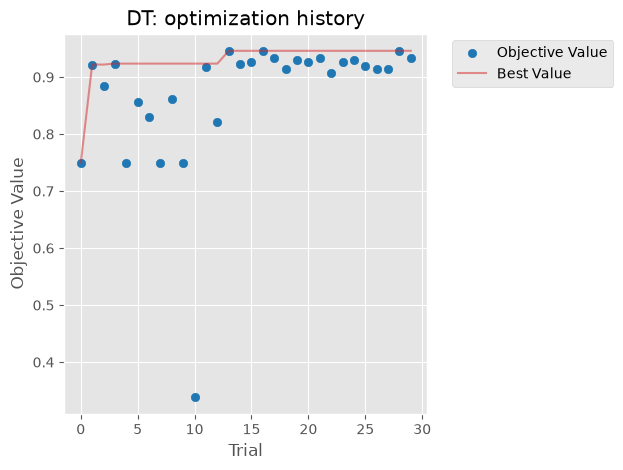

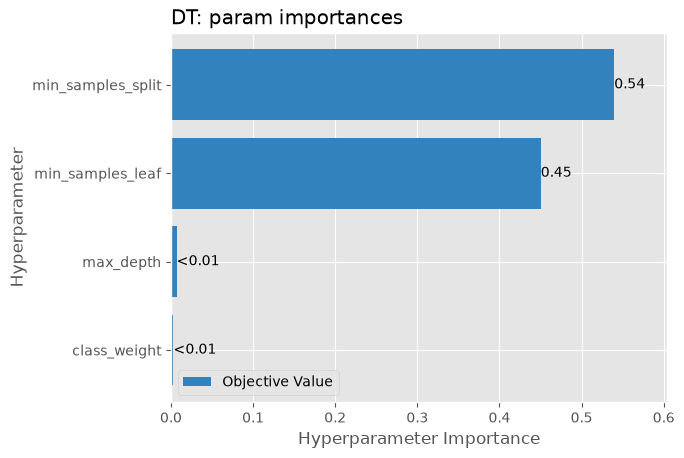

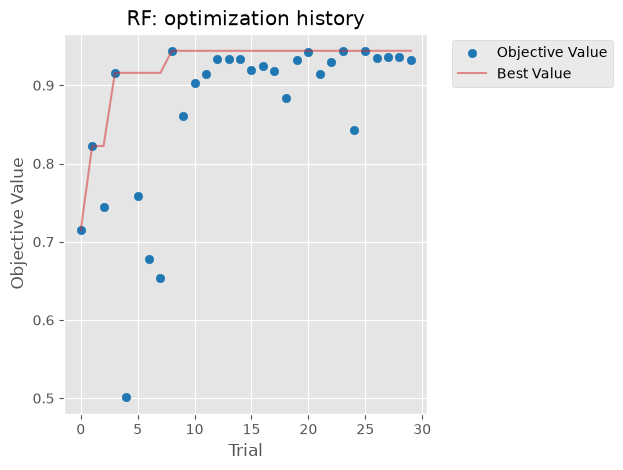

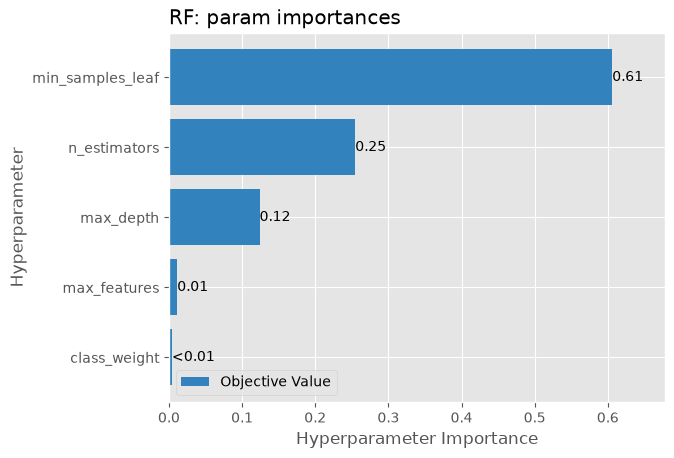

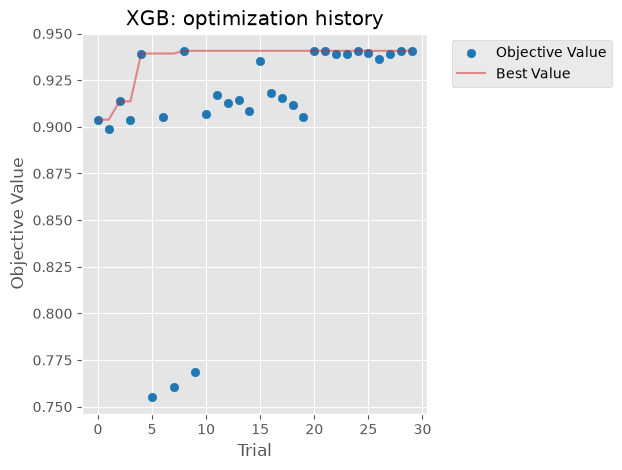

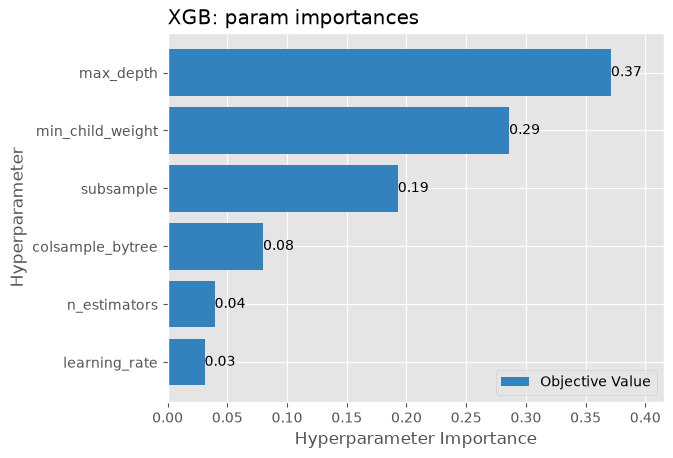

In [19]:
final_models = {n: build_pipeline(n, True, studies[n].best_params).fit(X_train, y_train) for n in models}

for name in models:
    optuna.visualization.matplotlib.plot_optimization_history(studies[name]).set_title(f'{name}: optimization history')
    plt.show()
    optuna.visualization.matplotlib.plot_param_importances(studies[name]).set_title(f'{name}: param importances', loc='left')
    plt.show()

**Висновок.** Оптимізація збіглася для всіх трьох моделей: найкраще значення знаходиться приблизно на 8–13 спробі,
а далі йде плато близько 0.94–0.945. Тож 30 спроб цілком достатньо. Найважливіші параметри:
- **DT:** `min_samples_split` і `min_samples_leaf`. Щоб виділити крихітний клас `1`, дереву потрібні маленькі листки.
- **RF:** `min_samples_leaf` (0.61), з тієї ж причини Optuna обрала `min_samples_leaf = 1`.
- **XGB:** `max_depth` і `min_child_weight`. Optuna обрала неглибокі дерева (`max_depth = 2`), але їх багато
  (249) і з невеликим `learning_rate`, тобто повільне і обережне навчання. Типові параметри XGBoost (глибина 6,
  lr 0.3) для 718 об'єктів занадто агресивні, тому XGB і виграв від тюнінгу найбільше.

---
## 5. Статистичне порівняння (скоригований t-тест Надо–Бенжіо)

Звичайний парний t-тест тут не підходить, бо тренувальні частини блоків перетинаються, і оцінки залежні.
Поправка Надо–Бенжіо збільшує дисперсію на доданок $n_{test}/n_{train}$. Беремо результати з п. 3 (однакові блоки).

In [20]:
def corrected_ttest(scores_a, scores_b, n_train, n_test):
    d = np.asarray(scores_a) - np.asarray(scores_b)
    kr = len(d)
    d_mean, d_var = d.mean(), d.var(ddof=1)
    if d_var == 0:
        return d_mean, 0.0, 1.0
    t = d_mean / np.sqrt(d_var * (1 / kr + n_test / n_train))
    p = 2 * stats.t.sf(abs(t), df=kr - 1)
    return d_mean, t, p


n_test_fold = len(X_train) // 5
n_train_fold = len(X_train) - n_test_fold
f1_of = lambda variant, name: cv_results[(variant, name)]['test_f1m']

comparisons = [(f'{n}: B vs A', f1_of('B', n), f1_of('A', n)) for n in models]
best_two = sorted(models, key=lambda n: f1_of('B', n).mean(), reverse=True)[:2]
comparisons.append((f'B: {best_two[0]} vs {best_two[1]}', f1_of('B', best_two[0]), f1_of('B', best_two[1])))

rows = []
for label, a, b in comparisons:
    d_mean, t, p = corrected_ttest(a, b, n_train_fold, n_test_fold)
    rows.append({'comparison': label, 'd_mean': round(d_mean, 4), 't': round(t, 3), 'p': round(p, 4),
                 'conclusion': 'significant' if p < 0.05 else 'not significant'})

**Таблиця 5.** Результати статистичного порівняння (α = 0.05)

In [21]:
pd.DataFrame(rows)

,comparison,d_mean,t,p,conclusion
0,DT: B vs A,0.0686,2.349,0.0340,significant
1,RF: B vs A,0.0572,3.405,0.0043,significant
2,XGB: B vs A,0.0400,1.019,0.3257,not significant
3,B: RF vs XGB,0.0158,0.527,0.6061,not significant


**Висновок.** Індикатори пропусків **статистично значуще** покращили DT (p = 0.034) і RF (p = 0.004). У XGB середня
різниця теж додатна (+0.04), але p = 0.33. Різниці між блоками в нього дуже різні, тому навіть з поправкою
Надо–Бенжіо цього недостатньо, щоб говорити про значущість. Різниця між двома найкращими моделями у варіанті B
(RF і XGB) лише 0.016 і **незначуща** (p = 0.61). Тобто сказати, що RF кращий за XGB, ми не можемо.

---
## 6. Фінальна оцінка на тестовій вибірці

In [22]:
test_rows = {}
for name in models:
    pred = final_models[name].predict(X_test)
    test_rows[name] = {'Accuracy': accuracy_score(y_test, pred),
                       'Macro F1': f1_score(y_test, pred, average='macro'),
                       'Balanced acc': balanced_accuracy_score(y_test, pred)}
table6 = pd.DataFrame(test_rows).T.round(4)
best_name = table6['Macro F1'].idxmax()
print('Best model on test:', best_name)

Best model on test: RF


**Таблиця 6.** Якість фінальних моделей на тесті

In [23]:
table6

,Accuracy,Macro F1,Balanced acc
DT,0.9944,0.9875,0.9985
RF,1.0000,1.0000,1.0000
XGB,1.0000,1.0000,1.0000


              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00       137
           5       1.00      1.00      1.00        13
           U       1.00      1.00      1.00         8

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180



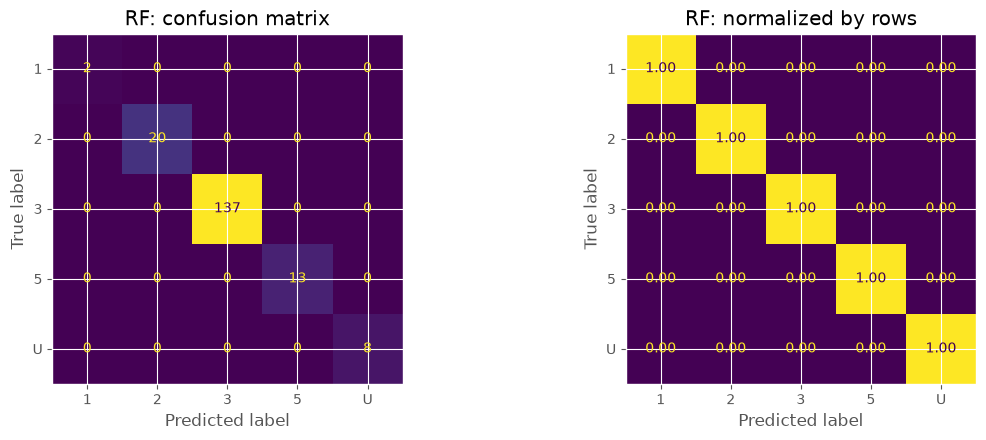

In [24]:
best_pred = final_models[best_name].predict(X_test)
print(classification_report(y_test, best_pred, target_names=le.classes_, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=le.classes_, ax=axes[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=le.classes_, normalize='true',
                                        values_format='.2f', ax=axes[1], colorbar=False)
axes[0].set_title(f'{best_name}: confusion matrix')
axes[1].set_title(f'{best_name}: normalized by rows')
plt.tight_layout()
plt.show()

**Висновок.** На тесті RF і XGB не помилились жодного разу (усі метрики 1.0), DT помилився один раз. Тестові
значення вищі, ніж на крос-валідації, і це не означає, що моделі раптом стали кращими. У тесті лише 2 об'єкти класу
`1` і 8 класу `U`. Якщо ці кілька об'єктів "легкі", macro F1 виходить 1.0. Якби хоч один об'єкт класу `1` був
помилковим, F1 цього класу впав би до ~0.67, і macro F1 просів би приблизно на 0.07. Тому оцінка на 180 об'єктах
дуже шумна, і більше довіри варта вкладена CV. Матриця плутанини для RF діагональна, плутанин у тесті немає.
Помилки видно лише на out-of-fold прогнозах у train (розділ 8): плутаються `2` і `3`, `3` і `U`, а рідкісний
клас `1` моделі відносять до `3` або `5`.

---
## 7. Важливість ознак

**MDI** (`feature_importances_`) рахується на ознаках після one-hot та індикаторів. Для XGBoost `feature_importances_`
за замовчуванням означає gain, це схожа ідея. **Permutation importance** рахуємо на тесті для всього пайплайну,
тобто на початкових ознаках.

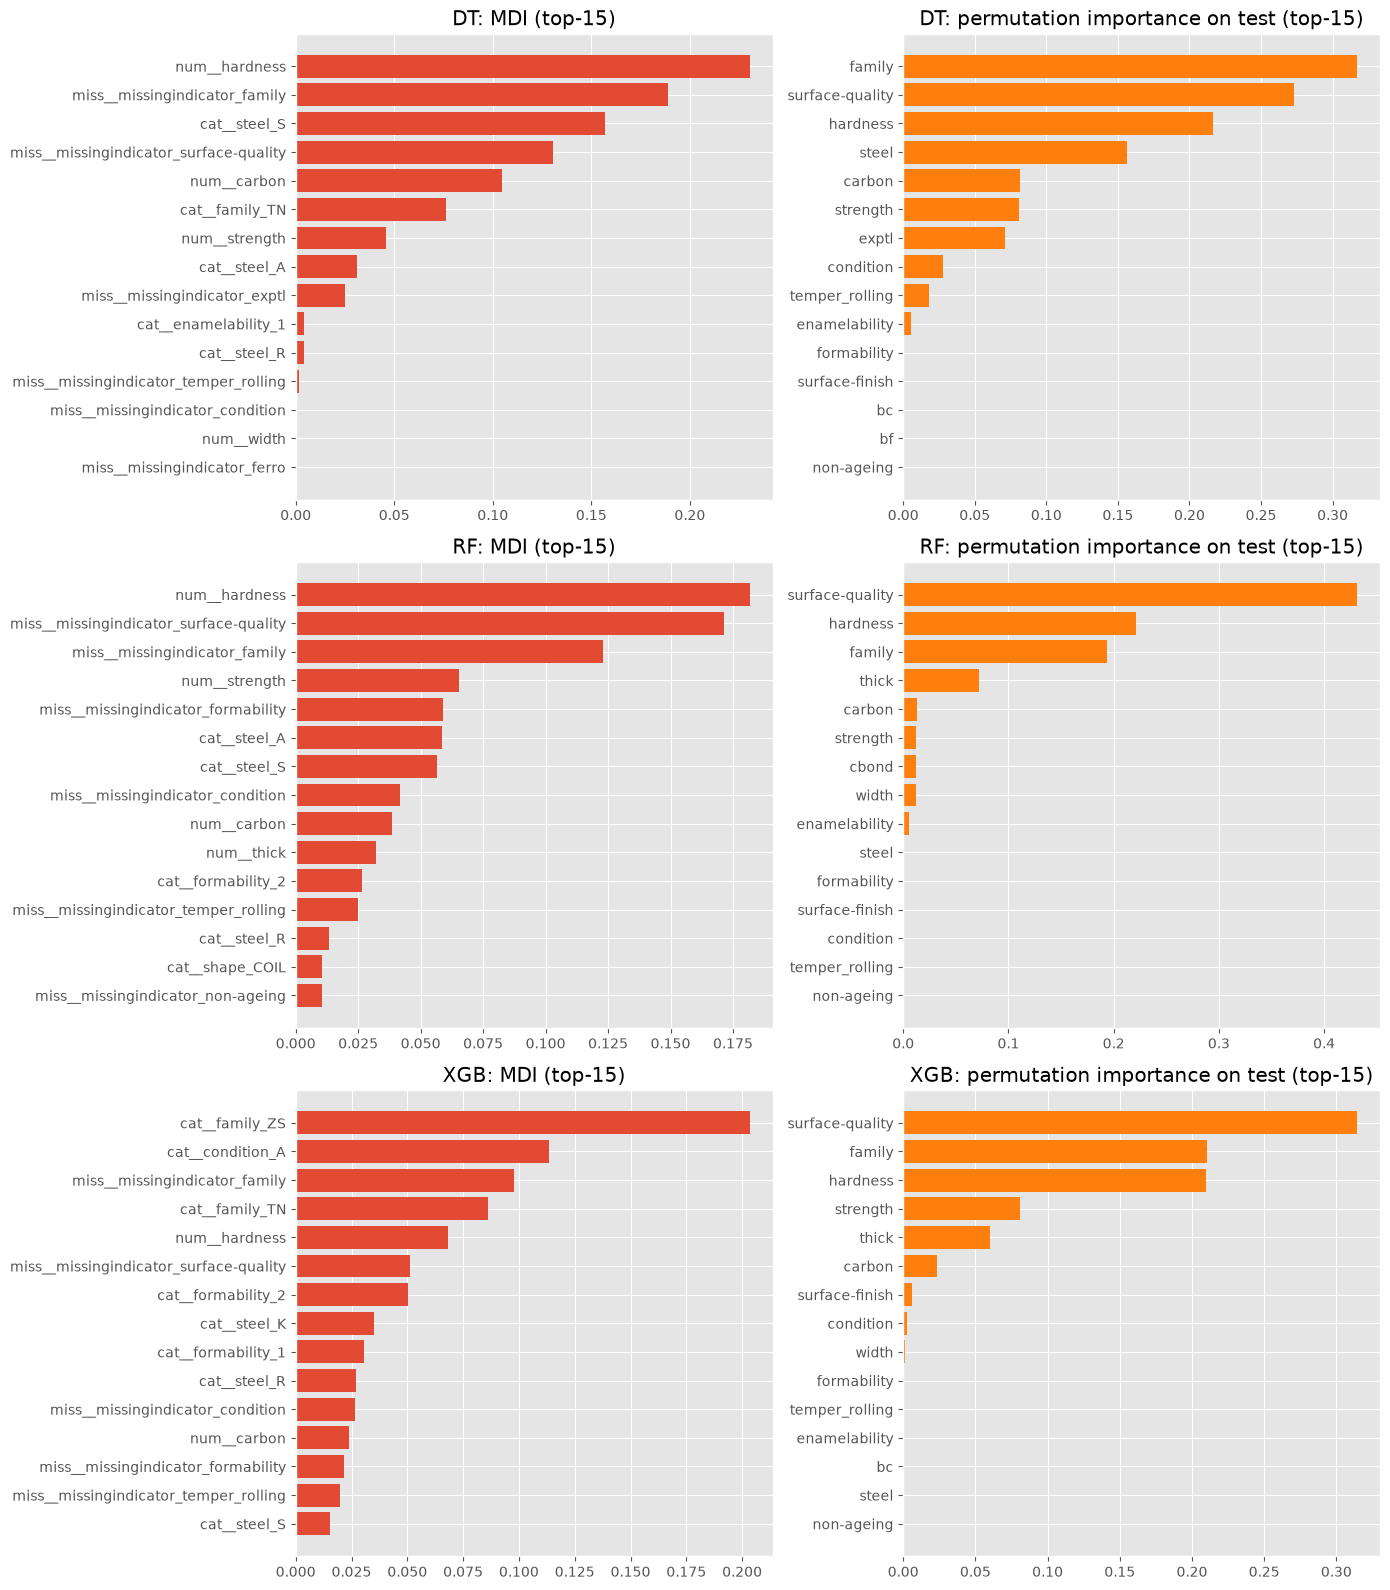

DT: missing indicators in MDI top-15 -> ['miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_exptl', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_condition', 'miss__missingindicator_ferro']
RF: missing indicators in MDI top-15 -> ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability', 'miss__missingindicator_condition', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_non-ageing']
XGB: missing indicators in MDI top-15 -> ['miss__missingindicator_family', 'miss__missingindicator_surface-quality', 'miss__missingindicator_condition', 'miss__missingindicator_formability', 'miss__missingindicator_temper_rolling']


In [25]:
mdi, perm = {}, {}
for name in models:
    pipe = final_models[name]
    names = pipe.named_steps['prep'].get_feature_names_out()
    mdi[name] = pd.Series(pipe.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
    res = permutation_importance(pipe, X_test, y_test, scoring='f1_macro', n_repeats=10,
                                 random_state=SEED, n_jobs=-1)
    perm[name] = pd.Series(res.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
for i, name in enumerate(models):
    top = mdi[name].head(15)[::-1]
    axes[i, 0].barh(top.index, top.values)
    axes[i, 0].set_title(f'{name}: MDI (top-15)')
    top = perm[name].head(15)[::-1]
    axes[i, 1].barh(top.index, top.values, color='tab:orange')
    axes[i, 1].set_title(f'{name}: permutation importance on test (top-15)')
plt.tight_layout()
plt.show()

for name in models:
    ind = [f for f in mdi[name].head(15).index if f.startswith('miss__')]
    print(f'{name}: missing indicators in MDI top-15 -> {ind}')

**Висновок.**
- **Індикатори пропусків у top-15 MDI є в усіх трьох моделях**, і досить високо: `missingindicator_family` і
  `missingindicator_surface-quality` у RF і DT займають 2–4 місця. Це сходиться з χ²-аналізом: пропуски залежать
  від класу, тому модель вчиться на самому факті "значення немає".
- **MDI і permutation importance загалом погоджуються** щодо лідерів: `hardness`, `family`, `surface-quality`,
  `steel`. Permutation importance рахується по сирій колонці, тому, перемішуючи `family`, ми перемішуємо і її
  пропуски. Звідси й високе місце `family` і `surface-quality`. Відрізняються вони в деталях: MDI в RF високо ставить
  `strength`, `carbon`, `thick`, а на тесті їх перемішування майже нічого не змінює. MDI зміщена на користь
  числових ознак з великою кількістю унікальних значень: у такої ознаки багато можливих порогів, і дерево частіше
  знаходить серед них "вдалий" випадковий поділ, навіть якщо реальної користі мало.
- **Між моделями важливості різні**, бо моделі будуються по-різному. Одне дерево жадібно бере одну ознаку з
  кількох схожих, і інші майже не використовує. RF на кожному поділі бачить випадкову підмножину ознак, тому
  важливість розмазується між схожими ознаками. XGB (тут gain) кожне нове дерево будує на помилках попередніх, і
  тому високо ставить ознаки, які допомагають саме на складних об'єктах (наприклад, `family_ZS`, `condition_A`).

---
## 8. Аналіз розбіжностей між моделями

Об'єкт вважається розбіжністю, якщо хоча б одна модель дала інший прогноз, ніж інші.

In [26]:
test_preds = pd.DataFrame({n: final_models[n].predict(X_test) for n in models}, index=X_test.index)
test_preds.insert(0, 'true', y_test)
disagree = test_preds[test_preds[models].nunique(axis=1) > 1].assign(source='test')
print('Disagreements on test:', len(disagree))

if len(disagree) < 3:
    # out-of-fold predictions on train, the models never see the object they predict
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = pd.DataFrame({n: cross_val_predict(build_pipeline(n, True, studies[n].best_params),
                                             X_train, y_train, cv=oof_cv) for n in models}, index=X_train.index)
    oof.insert(0, 'true', y_train)
    oof_dis = oof[oof[models].nunique(axis=1) > 1].assign(source='train (out-of-fold)')
    print('Disagreements on train (OOF):', len(oof_dis))
    disagree = pd.concat([disagree, oof_dis.head(3 - len(disagree))])

Disagreements on test: 1


Disagreements on train (OOF): 8


**Таблиця 7.** Об'єкти розбіжностей (класи в початкових позначеннях)

In [27]:
table7 = disagree.copy()
for c in ['true'] + models:
    table7[c] = le.classes_[table7[c]]
table7.rename(columns={'true': 'True class', 'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'})

,True class,Decision Tree,Random Forest,XGBoost,source
619,3,U,3,3,test
110,3,2,2,3,train (out-of-fold)
364,1,5,3,3,train (out-of-fold)


### Детальний аналіз одного об'єкта

In [28]:
obj_id = disagree.index[0]
x_raw = X.loc[[obj_id]]
print('Object', obj_id, '| source:', disagree.loc[obj_id, 'source'],
      '| true class:', le.classes_[disagree.loc[obj_id, 'true']])

prep = final_models['RF'].named_steps['prep']  # imputation is the same for all three models
num_imp = prep.named_transformers_['num']
cat_imp = prep.named_transformers_['cat'].named_steps['impute']
fill_values = pd.concat([pd.Series(num_imp.statistics_, index=num_imp.feature_names_in_),
                         pd.Series(cat_imp.statistics_, index=cat_imp.feature_names_in_)])

row = x_raw.iloc[0]
pd.DataFrame({'raw value': row,
              'missing': row.isna(),
              'filled with': [fill_values.get(c) if pd.isna(v) else '' for c, v in row.items()]})

Object 619 | source: test | true class: 3


,raw value,missing,filled with
family,NaN,True,TN
steel,A,False,
carbon,0,False,
hardness,80,False,
temper_rolling,T,False,
condition,NaN,True,S
formability,NaN,True,2
strength,0,False,
non-ageing,NaN,True,N
surface-finish,NaN,True,P


In [29]:
proba = pd.DataFrame({n: final_models[n].predict_proba(x_raw)[0] for n in models}, index=le.classes_).T.round(3)
proba['prediction'] = [le.classes_[final_models[n].predict(x_raw)[0]] for n in models]
proba

,1,2,3,5,U,prediction
DT,0.000,0.0,0.028,0.000,0.972,U
RF,0.000,0.0,0.654,0.000,0.346,3
XGB,0.014,0.0,0.683,0.001,0.302,3


DT (predicted class U):
num__hardness                             0.7876
num__width                               -0.0157
num__carbon                              -0.0122
miss__missingindicator_surface-quality    0.0064
miss__missingindicator_family             0.0027 

RF (predicted class 3):
miss__missingindicator_surface-quality    0.1518
num__hardness                            -0.1350
num__width                                0.1257
num__thick                                0.0812
miss__missingindicator_cbond              0.0632 

XGB (predicted class 3):
miss__missingindicator_surface-quality    1.1846
num__hardness                            -1.0927
num__thick                                0.4327
miss__missingindicator_condition         -0.3085
cat__steel_A                             -0.2034 



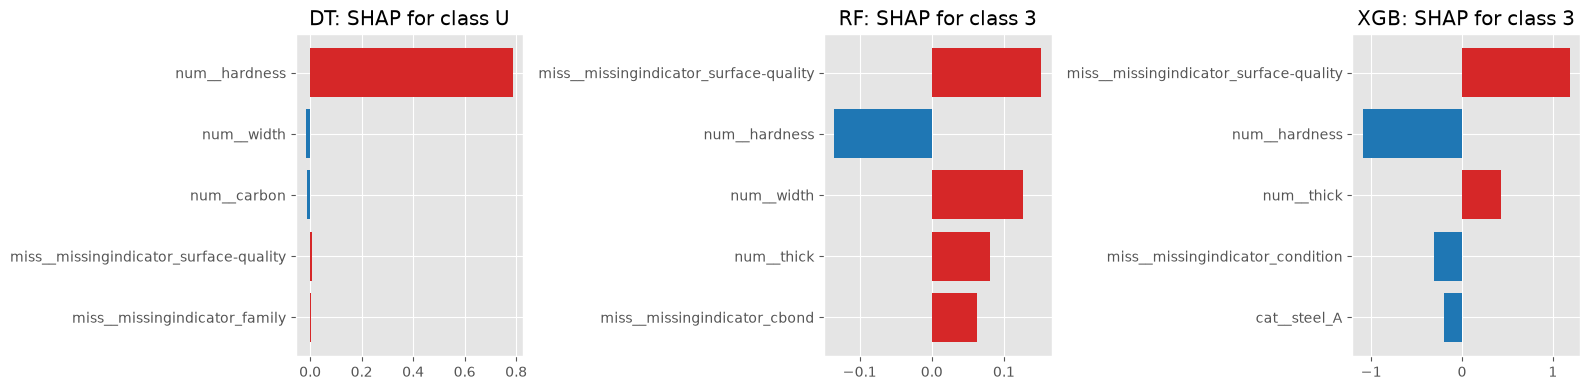

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, models):
    pipe = final_models[name]
    x_proc = pipe.named_steps['prep'].transform(x_raw)
    names = pipe.named_steps['prep'].get_feature_names_out()
    sv = np.asarray(shap.TreeExplainer(pipe.named_steps['clf']).shap_values(x_proc))  # (1, features, classes)
    pred = pipe.predict(x_raw)[0]
    contrib = pd.Series(sv[0, :, pred], index=names)
    top5 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    print(f'{name} (predicted class {le.classes_[pred]}):')
    print(top5.round(4).to_string(), '\n')
    ax.barh(top5.index[::-1], top5.values[::-1],
            color=['tab:red' if v > 0 else 'tab:blue' for v in top5.values[::-1]])
    ax.set_title(f'{name}: SHAP for class {le.classes_[pred]}')
plt.tight_layout()
plt.show()

**Висновок.** На тесті знайшлась лише 1 розбіжність (ефект стелі), тому ще 2 об'єкти взяті з train за
out-of-fold прогнозами (позначені в колонці `source`). Детально розбираємо тестовий об'єкт 619: справжній клас `3`,
DT каже `U`, RF і XGB кажуть `3`.

- Більшість ознак у цього об'єкта пропущені й заповнені модою, зокрема `condition`, `formability`, `enamelability`.
  У SHAP ці заповнені значення майже не впливають. Зате важливі індикатори пропусків: те, що `surface-quality`
  **не** пропущена (значення `G`), тягне RF і XGB до класу `3`.
- **DT** вирішує фактично однією ознакою: `hardness = 80` дає +0.79 до класу `U`. Об'єкт потрапив у листок за
  жорстким порогом, тому дерево впевнене на 97%. Це помилка, але дуже впевнена.
- **RF і XGB** теж бачать, що `hardness` тягне від класу `3` (від'ємний внесок), але їх рішення складається з багатьох
  ознак (`surface-quality`, `width`, `thick`), які переважують. Ансамбль усереднює багато дерев і не залежить від
  одного порогу.
- Ймовірності показують, що об'єкт лежить близько до межі `3`/`U`: RF дає 0.65 проти 0.35, XGB 0.68 проти 0.30.
  Тобто й ансамблі не дуже впевнені, і об'єкт справді складний.

(SHAP для XGB у логітах, а для DT/RF у ймовірностях, тому порівнювати варто знаки й порядок ознак, а не величини.)

---
## 9. Висновок

1. За вкладеною CV найкраща модель **RF** (macro F1 = 0.935 ± 0.081), XGB майже такий самий (0.931 ± 0.079).
   Розкид великий, бо в класі `1` всього 6 об'єктів у train, і різниця RF vs XGB статистично незначуща (p = 0.61),
   тому перевагу RF довести не можна.
2. Індикатори пропусків значно покращили всі моделі (+0.04…+0.07 macro F1), для DT і RF значуще. Це сходиться з
   χ²-аналізом (пропуски залежать від класу, тобто не MCAR) і з важливостями ознак: індикатори в top-15 MDI у всіх моделей.
3. `best_value` вищий за оцінку вкладеної CV: для RF і XGB приблизно на 0.01, для DT на 0.08. Отже, `best_value`
   як оцінка якості оптимістичний, особливо для нестабільної моделі, і чесну оцінку дає тільки вкладена CV.
4. Найбільше від оптимізації виграв XGB (0.909 → 0.931). Його типові параметри занадто агресивні для такого
   маленького датасету, а Optuna обрала неглибокі дерева з меншим learning rate.
5. Найскладніший клас `1`: у train лише 6 прикладів, і на out-of-fold прогнозах моделі правильно вгадують
   приблизно 4 з них. Кожна така помилка сильно б'є по macro F1. Ще плутаються пари `2`/`3` і `3`/`U`: у них
   схожі значення ознак, як показав розібраний об'єкт з межі `3`/`U`.
6. Розбіжностей мало, бо діє ефект стелі. Ті, що є, показують: DT помиляється через один жорсткий поріг
   (`hardness`) і при цьому дуже впевнений, а ансамблі спираються на багато ознак, зокрема на індикатори пропусків.
7. Для практики я б обрав **Random Forest**: найкраща і стабільна якість, менше залежить від гіперпараметрів, ніж
   XGB, вчиться швидко. Якщо головне – пояснити рішення людині, можна взяти одне дерево, але воно нестабільне
   і помітно гірше за якістю.